# Projeto Final — Análise de Dados

Notebook organizado em etapas para facilitar a execução e a visualização pelo professor.

**Como usar:** execute as células de cima para baixo (`Shift + Enter`). Confira os dados de conexão do MySQL e ajuste o caminho do CSV para o local onde ele está salvo no seu computador.

O projeto tem duas partes:
1. Consultas e análises de ocorrências aeronáuticas no MySQL.
2. Análises de Big Data sobre transporte aéreo a partir de um arquivo CSV/Parquet.


## 1. Importação das bibliotecas

In [26]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import polars as pl

## 2. Conectar ao banco de dados MySQL
Confira o endereço, usuário, senha e nome do banco antes de executar. A conexão precisa estar ativa para as próximas células.

In [27]:
conexao = mysql.connector.connect(
    host="127.0.0.1",
    port=3306,
    user="root",
    password="",
    database="meu_ecommerce"
)

cursor = conexao.cursor()
print("Conexao com o MySQL realizada com sucesso!")


Conexao com o MySQL realizada com sucesso!


## 3. Definir as consultas SQL
As seis consultas resumem ocorrências por classificação, estado, tipo, fator contribuinte, fabricante e situação das recomendações.

In [28]:
# ========================================================
# 2. DEFINIR AS PERGUNTAS E AS CONSULTAS SQL
# ========================================================

consultas = [

    {
        "pergunta": "1. Ocorrencias por classificacao",

        "query": """
            SELECT
                ocorrencia_classificacao,
                COUNT(*) AS total
            FROM ocorrencia
            WHERE ocorrencia_classificacao IS NOT NULL
            GROUP BY ocorrencia_classificacao
            ORDER BY total DESC
        """,

        "coluna": "ocorrencia_classificacao",
        "titulo": "Quantidade de Ocorrencias por Classificacao",
        "eixo_x": "Classificacao",
        "eixo_y": "Quantidade de ocorrencias"
    },


    {
        "pergunta": "2. Ocorrencias por estado",

        "query": """
            SELECT
                ocorrencia_uf,
                COUNT(*) AS total
            FROM ocorrencia
            WHERE ocorrencia_uf IS NOT NULL
              AND ocorrencia_uf <> ''
            GROUP BY ocorrencia_uf
            ORDER BY total DESC
        """,

        "coluna": "ocorrencia_uf",
        "titulo": "Quantidade de Ocorrencias por Estado",
        "eixo_x": "Estado",
        "eixo_y": "Quantidade de ocorrencias"
    },


    {
        "pergunta": "3. Tipos de ocorrencia mais registrados",

        "query": """
            SELECT
                ocorrencia_tipo,
                COUNT(*) AS total
            FROM ocorrencia_tipo
            WHERE ocorrencia_tipo IS NOT NULL
              AND ocorrencia_tipo <> ''
            GROUP BY ocorrencia_tipo
            ORDER BY total DESC
        """,

        "coluna": "ocorrencia_tipo",
        "titulo": "Frequencia dos Tipos de Ocorrencia",
        "eixo_x": "Tipo de ocorrencia",
        "eixo_y": "Quantidade de registros"
    },


    {
        "pergunta": "4. Fatores contribuintes mais frequentes",

        "query": """
            SELECT
                fator_nome,
                COUNT(*) AS total
            FROM fator_contribuinte
            WHERE fator_nome IS NOT NULL
              AND fator_nome <> ''
            GROUP BY fator_nome
            ORDER BY total DESC
        """,

        "coluna": "fator_nome",
        "titulo": "Frequencia dos Fatores Contribuintes",
        "eixo_x": "Fator contribuinte",
        "eixo_y": "Quantidade de registros"
    },


    {
        "pergunta": "5. Fabricantes de aeronaves mais frequentes",

        "query": """
            SELECT
                aeronave_fabricante,
                COUNT(*) AS total
            FROM aeronave
            WHERE aeronave_fabricante IS NOT NULL
              AND aeronave_fabricante <> ''
            GROUP BY aeronave_fabricante
            ORDER BY total DESC
        """,

        "coluna": "aeronave_fabricante",
        "titulo": "Quantidade de Registros por Fabricante",
        "eixo_x": "Fabricante",
        "eixo_y": "Quantidade de aeronaves"
    },


    {
        "pergunta": "6. Recomendacoes por situacao",

        "query": """
            SELECT
                recomendacao_status,
                COUNT(*) AS total
            FROM recomendacao
            WHERE recomendacao_status IS NOT NULL
              AND recomendacao_status <> ''
            GROUP BY recomendacao_status
            ORDER BY total DESC
        """,

        "coluna": "recomendacao_status",
        "titulo": "Quantidade de Recomendacoes por Situacao",
        "eixo_x": "Situacao da recomendacao",
        "eixo_y": "Quantidade de recomendacoes"
    }

]

## 4. Executar as consultas e gerar gráficos
Esta célula percorre as consultas definidas acima, mostra as tabelas de resultados e cria um gráfico de colunas para cada consulta.


1. OCORRENCIAS POR CLASSIFICACAO
ocorrencia_classificacao  total
               INCIDENTE  10363
                ACIDENTE   3003
         INCIDENTE GRAVE   1260


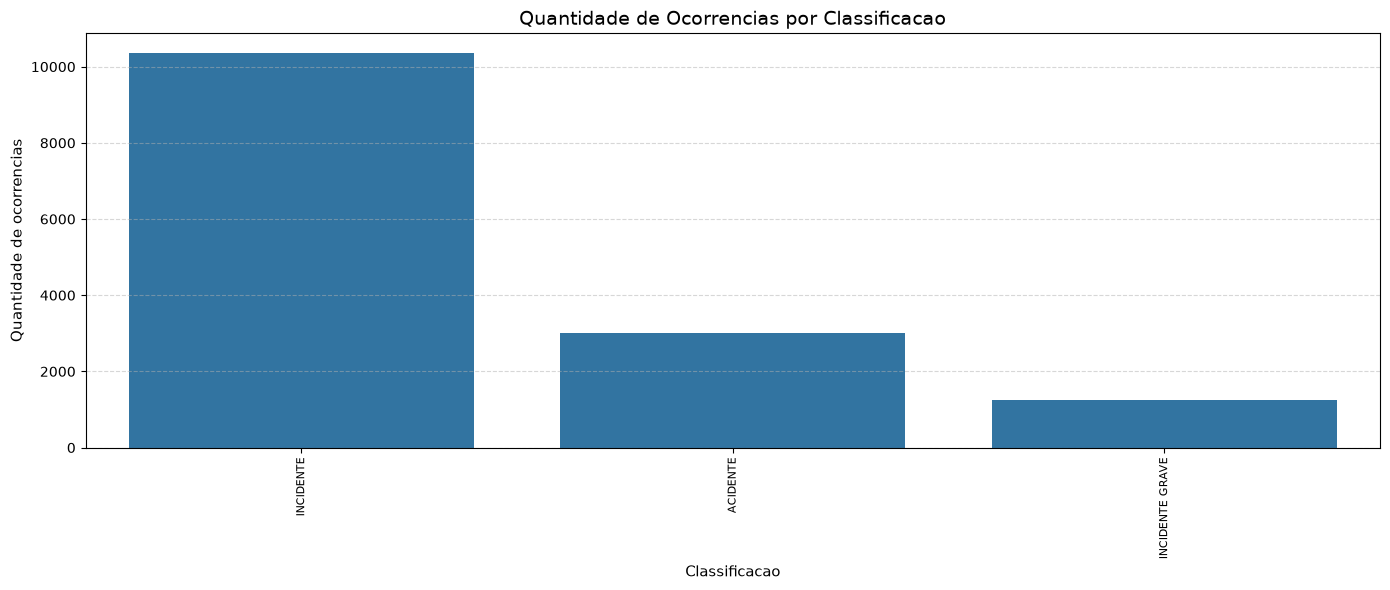


2. OCORRENCIAS POR ESTADO
ocorrencia_uf  total
           SP   3626
           RJ   1526
           MG   1224
           PR    988
           RS    776
           MT    665
           GO    664
           BA    655
           PA    621
           AM    526
           SC    518
           DF    473
           PE    441
           MS    353
           CE    268
           ES    188
           MA    186
           RR    169
           TO    125
           PI    118
           AC    116
           RO     92
           PB     76
           AL     71
           RN     56
           SE     44
           AP     36
           **     25


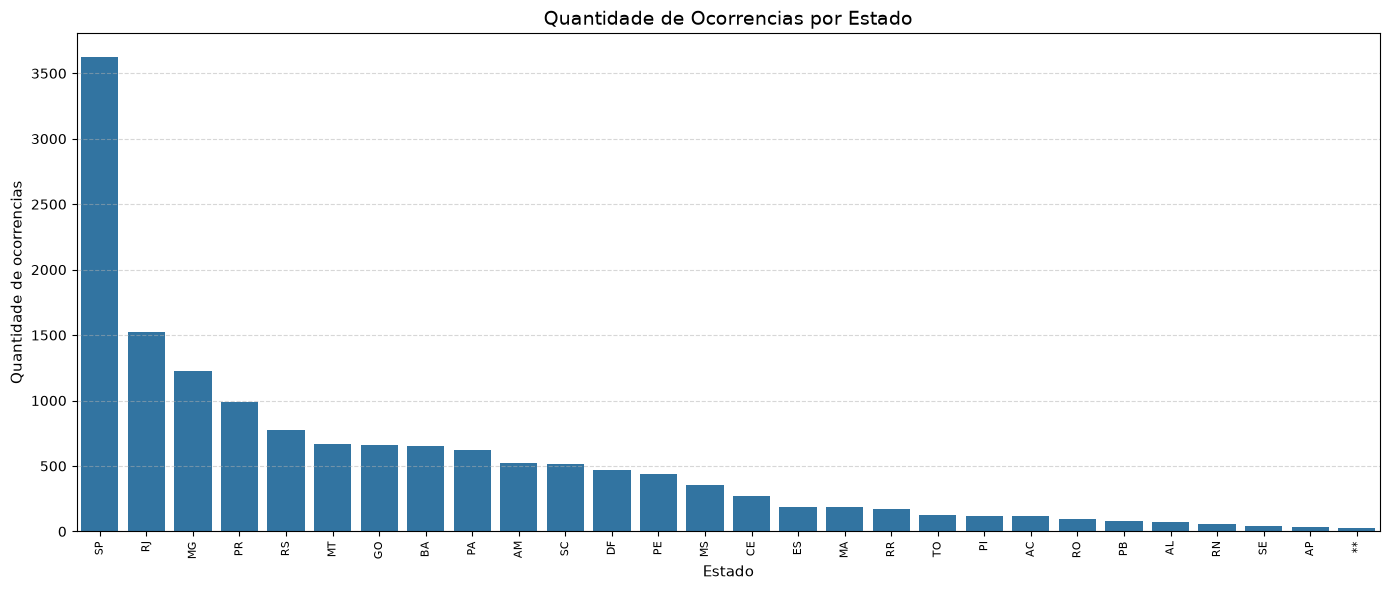


3. TIPOS DE OCORRENCIA MAIS REGISTRADOS
                                                                             ocorrencia_tipo  total
                                          FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPONENTE   3144
                                                                             COLISÃO COM AVE   2412
                                                                       FALHA DO MOTOR EM VOO   1134
                                                                             ESTOURO DE PNEU    902
                                                                   PERDA DE CONTROLE NO SOLO    754
                                                                           EXCURSÃO DE PISTA    712
                                                                    PERDA DE CONTROLE EM VOO    626
                                                         FALHA OU MAU FUNCIONAMENTO DO MOTOR    604
                                                           

C:\Users\jefferson.mota\AppData\Local\Temp\ipykernel_23276\991596423.py:85: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


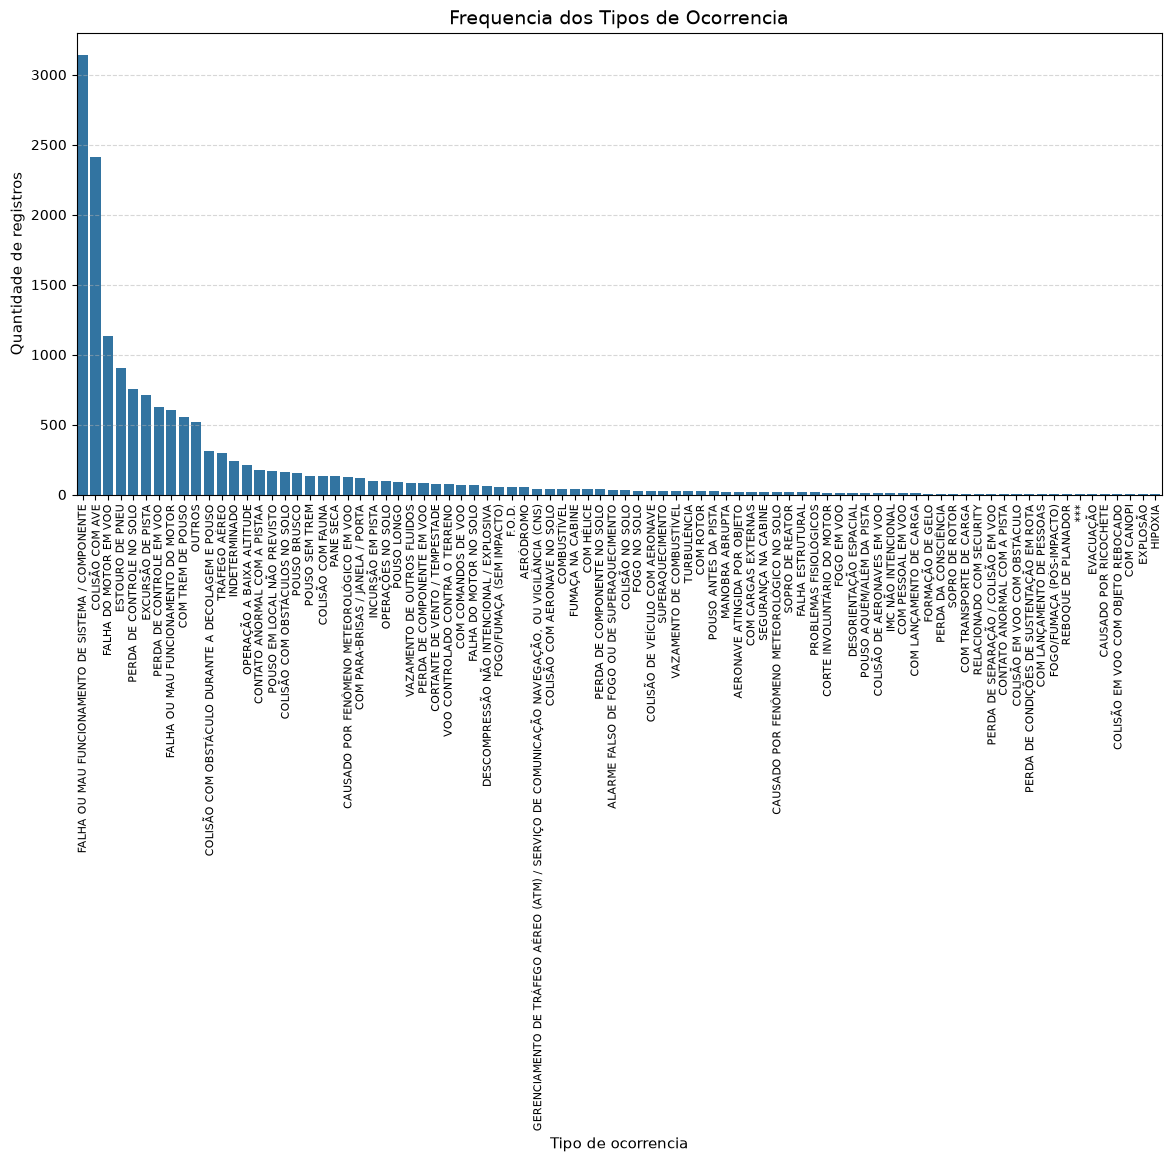


4. FATORES CONTRIBUINTES MAIS FREQUENTES
                               fator_nome  total
                  JULGAMENTO DE PILOTAGEM   1158
                    APLICAÇÃO DE COMANDOS    822
                     SUPERVISÃO GERENCIAL    679
                      PLANEJAMENTO DE VOO    642
                   MANUTENÇÃO DA AERONAVE    544
                                  ATITUDE    529
                       PROCESSO DECISÓRIO    493
              POUCA EXPERIÊNCIA DO PILOTO    354
                                PERCEPÇÃO    346
                                INSTRUÇÃO    252
        CONDIÇÕES METEOROLÓGICAS ADVERSAS    250
                      INDISCIPLINA DE VOO    232
                                  ATENÇÃO    231
                              OUTRO FATOR    214
                    COORDENAÇÃO DE CABINE    205
                CAPACITAÇÃO E TREINAMENTO    178
                PROCESSOS ORGANIZACIONAIS    172
                        SISTEMAS DE APOIO    157
             INFRAESTRUTURA

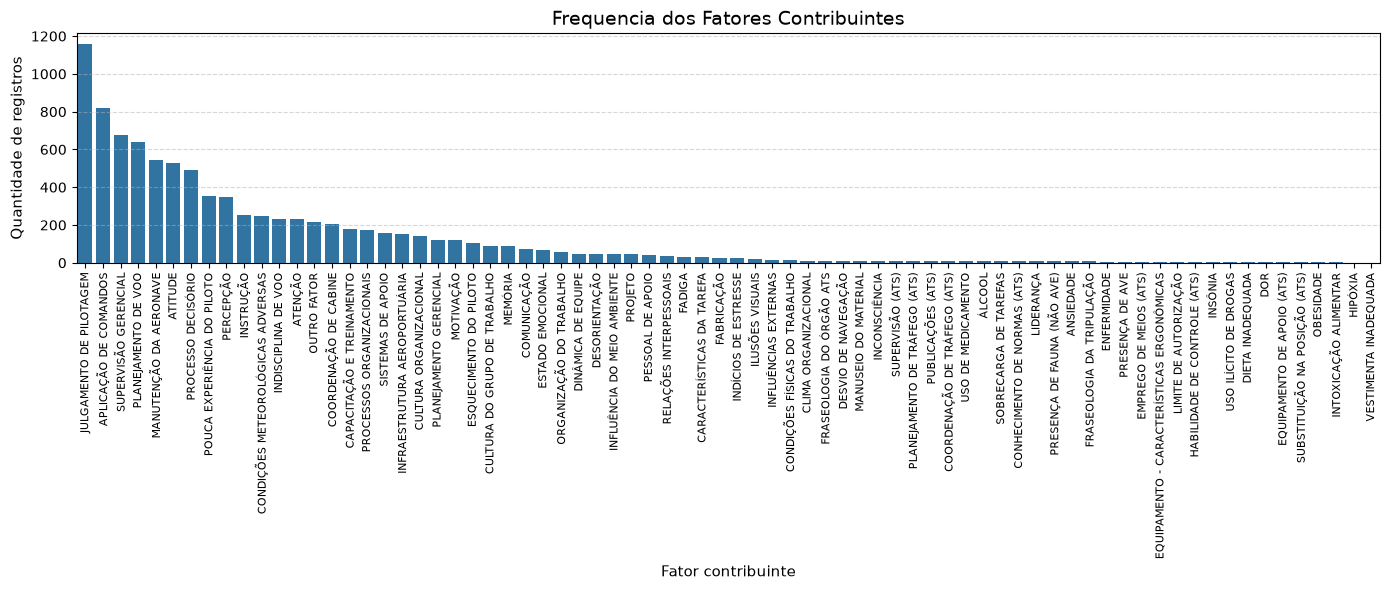


5. FABRICANTES DE AERONAVES MAIS FREQUENTES
                              aeronave_fabricante  total
                                          EMBRAER   1708
                                  CESSNA AIRCRAFT   1700
                                           BOEING   1426
                                           AIRBUS   1373
                                   PIPER AIRCRAFT    738
                                            NEIVA    700
           ATR - GIE AVIONS DE TRANSPORT RÉGIONAL    670
                                   BOEING COMPANY    634
                                     DESCONHECIDO    520
                                   BEECH AIRCRAFT    508
                                    AIRBUS S.A.S.    449
                      NEIVA INDUSTRIA AERONAUTICA    424
                                       AERO BOERO    339
                              ROBINSON HELICOPTER    278
                                 AIRBUS INDUSTRIE    246
                                         HE

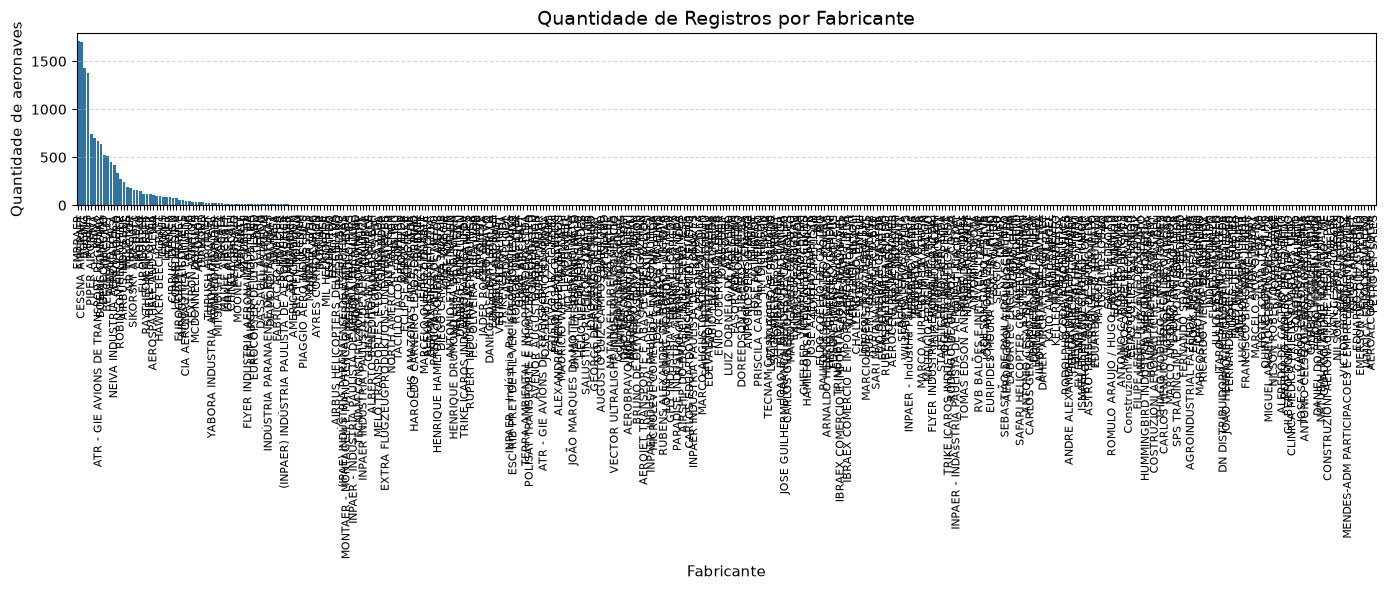


6. RECOMENDACOES POR SITUACAO
         recomendacao_status  total
                     ADOTADA   1844
                         ***    592
                 NÃO ADOTADA    173
ADOTADA DE FORMA ALTERNATIVA    152
         AGUARDANDO RESPOSTA     18
               NÃO APLICÁVEL     10


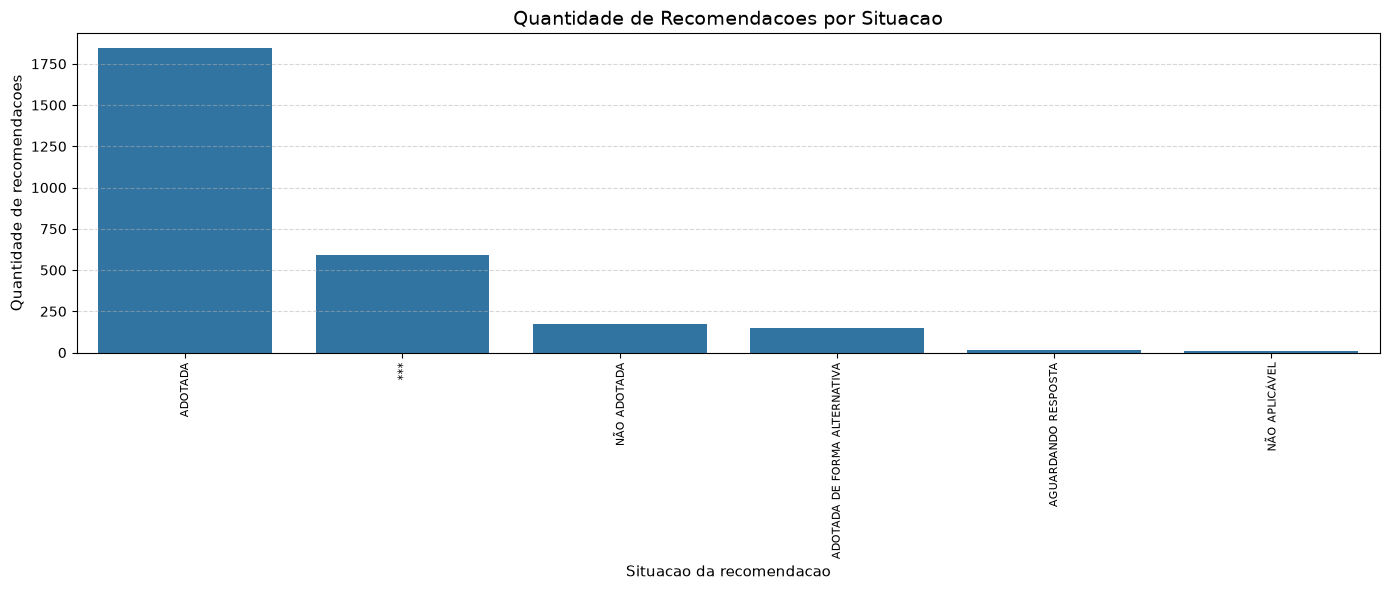

In [29]:
# ========================================================
# 3. EXECUTAR AS CONSULTAS
# ========================================================

for analise in consultas:

    print("\n" + "=" * 80)
    print(analise["pergunta"].upper())
    print("=" * 80)


    # Executar a consulta SQL
    cursor.execute(analise["query"])


    # Obter os resultados
    resultados = cursor.fetchall()


    # Obter os nomes das colunas
    colunas = [
        coluna[0] for coluna in cursor.description
    ]


    # Criar um DataFrame com os resultados
    df = pd.DataFrame(
        resultados,
        columns=colunas
    )


    # Exibir os resultados no terminal
    if not df.empty:

        print(df.to_string(index=False))


        # ================================================
        # 4. GERAR O GRAFICO DE COLUNAS
        # ================================================

        plt.figure(figsize=(14, 6))


        sns.barplot(
            data=df,
            x=analise["coluna"],
            y="total"
        )


        plt.title(
            analise["titulo"],
            fontsize=14
        )


        plt.xlabel(
            analise["eixo_x"],
            fontsize=11
        )


        plt.ylabel(
            analise["eixo_y"],
            fontsize=11
        )


        # Girar os nomes para facilitar a leitura
        plt.xticks(
            rotation=90,
            fontsize=8
        )


        plt.grid(
            axis="y",
            linestyle="--",
            alpha=0.5
        )


        plt.tight_layout()
        plt.show()


    else:

        print("Nenhum resultado encontrado.")

## 5. Preparar os dados de fatalidades e calcular estatísticas
Calcula média, mediana, desvio padrão, assimetria e curtose, além de apresentar uma interpretação simples dos dois últimos indicadores.

In [6]:
# ========================================================
# 5. ANALISE ESTATISTICA DAS FATALIDADES - AULA 09
# ========================================================

print("\n" + "=" * 80)
print("7. DISTRIBUICAO DAS FATALIDADES NAS OCORRENCIAS AERONAUTICAS")
print("=" * 80)


# Consulta dos dados de fatalidades
query_fatalidades = """
    SELECT
        aeronave_fatalidades_total
    FROM aeronave
    WHERE aeronave_fatalidades_total IS NOT NULL
"""


cursor.execute(query_fatalidades)


# Obter os resultados
resultados_fatalidades = cursor.fetchall()


# Criar DataFrame
df_fatalidades = pd.DataFrame(
    resultados_fatalidades,
    columns=["aeronave_fatalidades_total"]
)


# Selecionar os dados
dados_fatalidades = df_fatalidades["aeronave_fatalidades_total"]


# ========================================================
# CALCULAR AS MEDIDAS ESTATISTICAS
# ========================================================

media_fatalidades = dados_fatalidades.mean()

mediana_fatalidades = dados_fatalidades.median()

desvio_padrao_fatalidades = dados_fatalidades.std()


# Calcular Assimetria
assimetria_fatalidades = dados_fatalidades.skew()


# Calcular Curtose
curtose_excesso_fatalidades = dados_fatalidades.kurtosis()

curtose_real_fatalidades = curtose_excesso_fatalidades + 3


# ========================================================
# EXIBIR RESULTADOS
# ========================================================

print(f"Media: {media_fatalidades:.2f}")

print(f"Mediana: {mediana_fatalidades:.2f}")

print(f"Desvio Padrao: {desvio_padrao_fatalidades:.2f}")

print(f"Assimetria: {assimetria_fatalidades:.4f}")

print(f"Curtose Real: {curtose_real_fatalidades:.4f}")


# ========================================================
# INTERPRETACAO DA ASSIMETRIA
# ========================================================

if assimetria_fatalidades >= -0.5 and assimetria_fatalidades <= 0.5:

    print(
        "-> Distribuicao aproximadamente simetrica."
    )

elif assimetria_fatalidades > 0.5:

    print(
        "-> Distribuicao assimetrica positiva."
    )

else:

    print(
        "-> Distribuicao assimetrica negativa."
    )


# ========================================================
# INTERPRETACAO DA CURTOSE
# ========================================================

if curtose_real_fatalidades >= 2.5 and curtose_real_fatalidades <= 3.5:

    print(
        "-> Distribuicao mesocurtica."
    )

elif curtose_real_fatalidades < 2.5:

    print(
        "-> Distribuicao platicurtica."
    )

else:

    print(
        "-> Distribuicao leptocurtica."
    )


7. DISTRIBUICAO DAS FATALIDADES NAS OCORRENCIAS AERONAUTICAS
Media: 0.11
Mediana: 0.00
Desvio Padrao: 1.81
Assimetria: 92.2794
Curtose Real: 9876.7279
-> Distribuicao assimetrica positiva.
-> Distribuicao leptocurtica.


## 6. Gráfico boxplot das fatalidades

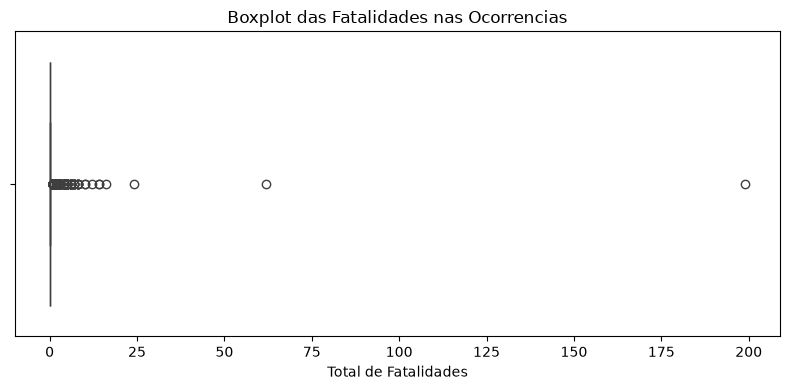

In [7]:
# ========================================================
# 6. BOXPLOT
# ========================================================

plt.figure(figsize=(8, 4))


sns.boxplot(
    x=dados_fatalidades
)


plt.title(
    "Boxplot das Fatalidades nas Ocorrencias"
)


plt.xlabel(
    "Total de Fatalidades"
)


plt.tight_layout()
plt.show()

## 7. Histograma das fatalidades
O histograma mostra a distribuição dos dados e inclui linhas para a média e a mediana.

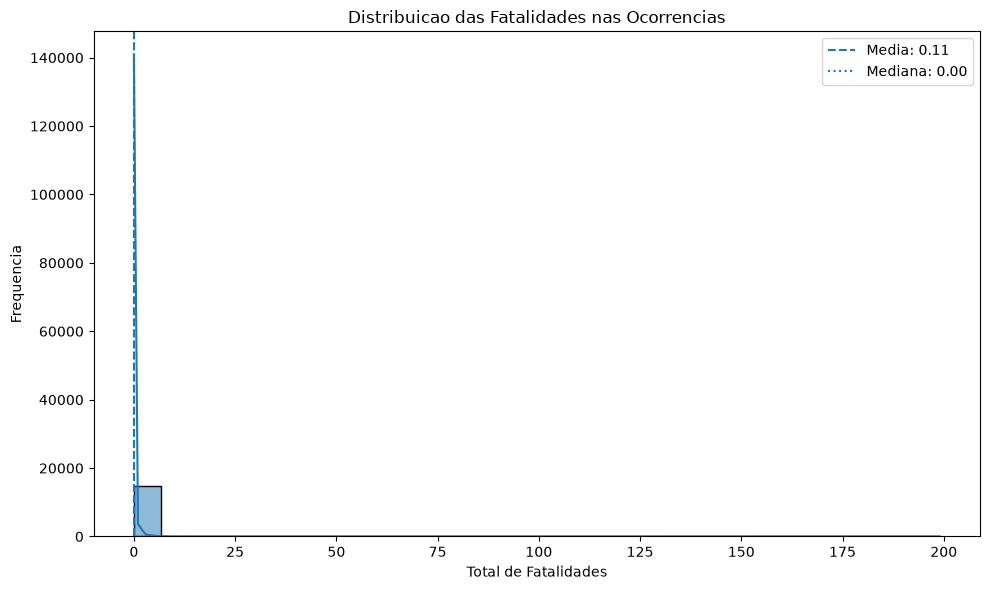

In [8]:
# ========================================================
# 7. HISTOGRAMA COM KDE
# ========================================================

plt.figure(figsize=(10, 6))


sns.histplot(
    dados_fatalidades,
    kde=True,
    bins=30
)


# Linha da media
plt.axvline(
    media_fatalidades,
    linestyle="--",
    label=f"Media: {media_fatalidades:.2f}"
)


# Linha da mediana
plt.axvline(
    mediana_fatalidades,
    linestyle=":",
    label=f"Mediana: {mediana_fatalidades:.2f}"
)


plt.title(
    "Distribuicao das Fatalidades nas Ocorrencias"
)


plt.xlabel(
    "Total de Fatalidades"
)


plt.ylabel(
    "Frequencia"
)


plt.legend()

plt.tight_layout()

plt.show()

## 8. Fechar a conexão com o MySQL
Execute esta célula depois de terminar todas as análises que usam o banco de dados. Ela fecha o cursor e a conexão aberta na etapa 2.


In [9]:
if cursor is not None:
    cursor.close()

if conexao is not None and conexao.is_connected():
    conexao.close()

print("\nConexao com o MySQL encerrada.")


Conexao com o MySQL encerrada.


## 9. Abrir a base de Big Data

**Atenção:** altere a variável `arquivo` para o caminho correto do arquivo `Dados_Estatisticos.csv` no seu computador. Esta célula carrega a base e mostra o título do projeto.

In [11]:
# ============================================================
# 1. LOCALIZAR E ABRIR A BASE BIG DATA
# ============================================================

# Substitua pelo caminho real do seu arquivo
arquivo = r"C:\\Users\\jefferson.mota\\Documents\\BIGDATA\\AnaliseBigData.senac\\aulas-modulo_2\\semana-04\\arquivos-projetos\\Dados_Estatisticos.csv"

if not os.path.exists(arquivo):
    print("Arquivo não encontrado. Corrija o caminho.")
    raise SystemExit

if arquivo.lower().endswith(".parquet"):
    dados = pl.scan_parquet(arquivo)

elif arquivo.lower().endswith(".csv"):
    dados = pl.scan_csv(
        arquivo,
        separator=";",
        encoding="utf8-lossy",
        infer_schema_length=1000
    )

else:
    print("Formato não suportado neste exemplo.")
    raise SystemExit

print("=" * 70)
print("PROJETO BIG DATA - TRANSPORTE AÉREO")
print("=" * 70)


PROJETO BIG DATA - TRANSPORTE AÉREO


## 10. Informações gerais da base
Mostra as colunas disponíveis e o total de registros.

In [12]:
# ============================================================
# 2. INFORMAÇÕES GERAIS DA BASE
# ============================================================

schema = dados.collect_schema()

print("\nCOLUNAS DA BASE:")
print(schema)

total_registros = dados.select(
    pl.len().alias("TOTAL_REGISTROS")
).collect()

print("\nTOTAL DE REGISTROS:")
print(total_registros)



COLUNAS DA BASE:
Schema({'EMPRESA_SIGLA': String, 'EMPRESA_NOME': String, 'EMPRESA_NACIONALIDADE': String, 'ANO': Int64, 'MES': Int64, 'AEROPORTO_DE_ORIGEM_SIGLA': String, 'AEROPORTO_DE_ORIGEM_NOME': String, 'AEROPORTO_DE_ORIGEM_UF': String, 'AEROPORTO_DE_ORIGEM_REGIAO': String, 'AEROPORTO_DE_ORIGEM_PAIS': String, 'AEROPORTO_DE_ORIGEM_CONTINENTE': String, 'AEROPORTO_DE_DESTINO_SIGLA': String, 'AEROPORTO_DE_DESTINO_NOME': String, 'AEROPORTO_DE_DESTINO_UF': String, 'AEROPORTO_DE_DESTINO_REGIAO': String, 'AEROPORTO_DE_DESTINO_PAIS': String, 'AEROPORTO_DE_DESTINO_CONTINENTE': String, 'NATUREZA': String, 'GRUPO_DE_VOO': String, 'PASSAGEIROS_PAGOS': Int64, 'PASSAGEIROS_GRATIS': Int64, 'CARGA_PAGA_KG': Int64, 'CARGA_GRATIS_KG': Int64, 'CORREIO_KG': Int64, 'ASK': Int64, 'RPK': Int64, 'ATK': Int64, 'RTK': Int64, 'COMBUSTIVEL_LITROS': Int64, 'DISTANCIA_VOADA_KM': Int64, 'DECOLAGENS': Int64, 'CARGA_PAGA_KM': Int64, 'CARGA_GRATIS_KM': Int64, 'CORREIO_KM': Int64, 'ASSENTOS': Int64, 'PAYLOAD': Int6

## 11. Verificar valores ausentes
Conta quantos valores nulos existem em cada coluna e exibe apenas as colunas que possuem valores ausentes.

In [13]:
# ============================================================
# 3. VERIFICAR VALORES AUSENTES
# ============================================================

print("\nVALORES AUSENTES POR COLUNA:")

valores_ausentes = dados.select(
    [
        pl.col(coluna).null_count().alias(coluna)
        for coluna in schema.names()
    ]
).collect()

ausentes_df = valores_ausentes.transpose(
    include_header=True,
    header_name="COLUNA",
    column_names=["VALORES_AUSENTES"]
)

ausentes_df = ausentes_df.filter(
    pl.col("VALORES_AUSENTES") > 0
).sort(
    "VALORES_AUSENTES",
    descending=True
)

print(ausentes_df)



VALORES AUSENTES POR COLUNA:
shape: (27, 2)
┌────────────────────────────────┬──────────────────┐
│ COLUNA                         ┆ VALORES_AUSENTES │
│ ---                            ┆ ---              │
│ str                            ┆ u32              │
╞════════════════════════════════╪══════════════════╡
│ COMBUSTIVEL_LITROS             ┆ 212012           │
│ RTK                            ┆ 141542           │
│ CARGA_GRATIS_KM                ┆ 141542           │
│ ASK                            ┆ 141536           │
│ ATK                            ┆ 141536           │
│ …                              ┆ …                │
│ AEROPORTO_DE_ORIGEM_SIGLA      ┆ 1812             │
│ AEROPORTO_DE_ORIGEM_NOME       ┆ 1812             │
│ AEROPORTO_DE_ORIGEM_PAIS       ┆ 1812             │
│ AEROPORTO_DE_ORIGEM_CONTINENTE ┆ 1812             │
│ GRUPO_DE_VOO                   ┆ 1                │
└────────────────────────────────┴──────────────────┘


## 12. Preparar as colunas
Converte a coluna `HORAS_VOADAS`, que usa vírgula como separador decimal, para um formato numérico.

In [14]:
# ============================================================
# 4. PREPARAR AS COLUNAS PARA AS ANALISES
# ============================================================

# Converte horas, que estão como texto, para número.
# Exemplo: "373,62" passa a representar 373.62.
dados = dados.with_columns(
    pl.col("HORAS_VOADAS")
    .str.replace_all(",", ".")
    .cast(pl.Float64, strict=False)
    .alias("HORAS_VOADAS_NUM")
)


## 13. Análise 1 — Passageiros por ano
Compara a quantidade anual de passageiros pagos e gratuitos.


ANALISE 1 - PASSAGEIROS POR ANO
shape: (19, 3)
┌──────┬───────────────────┬────────────────────┐
│ ANO  ┆ PASSAGEIROS_PAGOS ┆ PASSAGEIROS_GRATIS │
│ ---  ┆ ---               ┆ ---                │
│ i64  ┆ i64               ┆ i64                │
╞══════╪═══════════════════╪════════════════════╡
│ 2007 ┆ 59611480          ┆ 1164346            │
│ 2008 ┆ 63378804          ┆ 1413648            │
│ 2009 ┆ 69555497          ┆ 1648427            │
│ 2010 ┆ 85343074          ┆ 1711129            │
│ 2011 ┆ 99766620          ┆ 2018289            │
│ …    ┆ …                 ┆ …                  │
│ 2021 ┆ 67413559          ┆ 1348580            │
│ 2022 ┆ 98021465          ┆ 2062846            │
│ 2023 ┆ 113052661         ┆ 2309812            │
│ 2024 ┆ 119186351         ┆ 2173965            │
│ 2025 ┆ 37557107          ┆ 709153             │
└──────┴───────────────────┴────────────────────┘


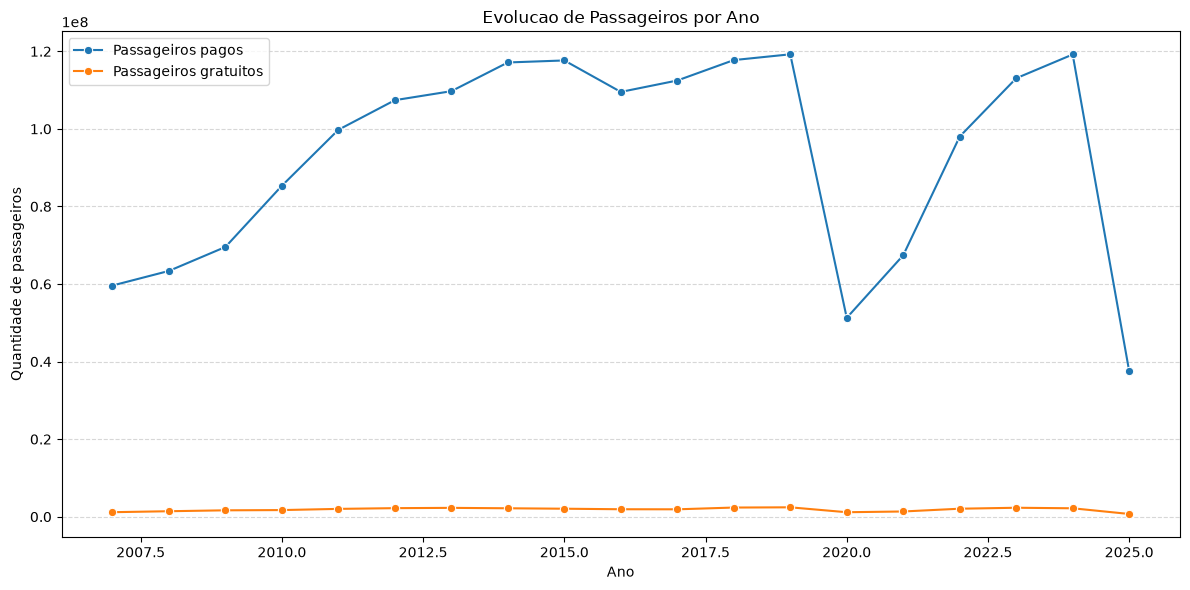

In [15]:
# ============================================================
# 5. ANALISE 1 - PASSAGEIROS POR ANO
# ============================================================

print("\n" + "=" * 70)
print("ANALISE 1 - PASSAGEIROS POR ANO")
print("=" * 70)

passageiros_ano = (
    dados.group_by("ANO")
    .agg(
        pl.col("PASSAGEIROS_PAGOS")
        .sum()
        .alias("PASSAGEIROS_PAGOS"),

        pl.col("PASSAGEIROS_GRATIS")
        .sum()
        .alias("PASSAGEIROS_GRATIS")
    )
    .sort("ANO")
    .collect()
)

print(passageiros_ano)

df_ano = passageiros_ano.to_pandas()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_ano,
    x="ANO",
    y="PASSAGEIROS_PAGOS",
    marker="o",
    label="Passageiros pagos"
)

sns.lineplot(
    data=df_ano,
    x="ANO",
    y="PASSAGEIROS_GRATIS",
    marker="o",
    label="Passageiros gratuitos"
)

plt.title("Evolucao de Passageiros por Ano")
plt.xlabel("Ano")
plt.ylabel("Quantidade de passageiros")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# ============================================================

## 14. Análise 2 — Decolagens por ano
Agrupa as decolagens por ano e apresenta um gráfico de barras.


ANALISE 2 - DECOLAGENS POR ANO
shape: (19, 2)
┌──────┬────────────┐
│ ANO  ┆ DECOLAGENS │
│ ---  ┆ ---        │
│ i64  ┆ i64        │
╞══════╪════════════╡
│ 2007 ┆ 744758     │
│ 2008 ┆ 766171     │
│ 2009 ┆ 838702     │
│ 2010 ┆ 968738     │
│ 2011 ┆ 1099644    │
│ …    ┆ …          │
│ 2021 ┆ 605034     │
│ 2022 ┆ 840533     │
│ 2023 ┆ 928152     │
│ 2024 ┆ 944156     │
│ 2025 ┆ 341027     │
└──────┴────────────┘


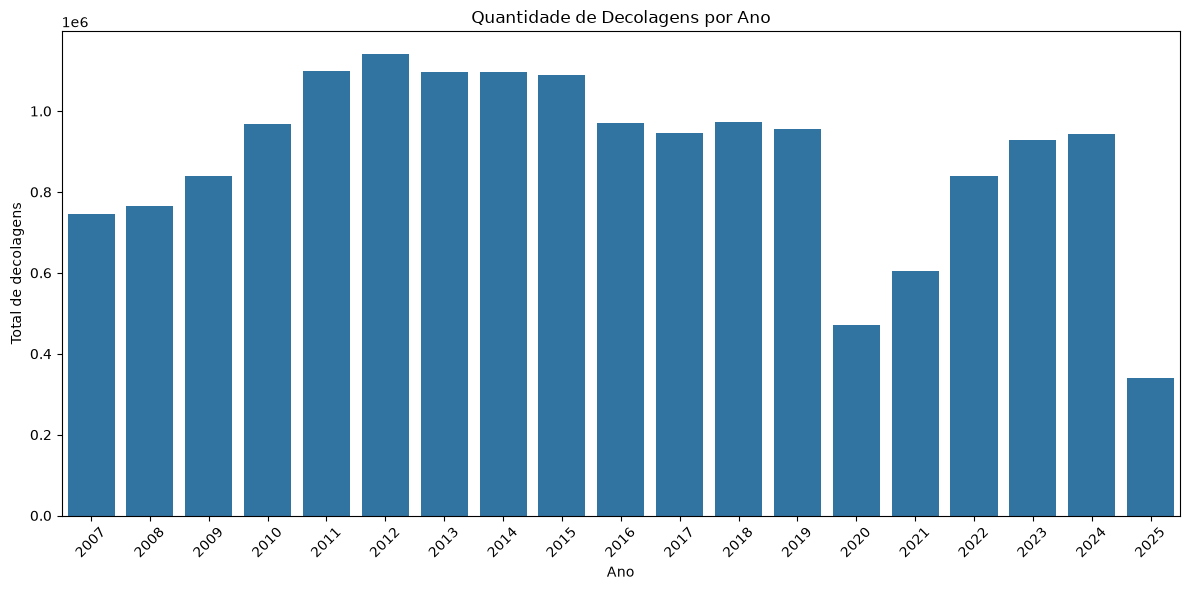

In [16]:
# 6. ANALISE 2 - DECOLAGENS POR ANO
# ============================================================

print("\n" + "=" * 70)
print("ANALISE 2 - DECOLAGENS POR ANO")
print("=" * 70)

decolagens_ano = (
    dados.group_by("ANO")
    .agg(
        pl.col("DECOLAGENS").sum().alias("DECOLAGENS")
    )
    .sort("ANO")
    .collect()
)

print(decolagens_ano)

df_decolagens = decolagens_ano.to_pandas()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_decolagens,
    x="ANO",
    y="DECOLAGENS"
)

plt.title("Quantidade de Decolagens por Ano")
plt.xlabel("Ano")
plt.ylabel("Total de decolagens")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================

## 15. Análise 3 — Companhias com mais passageiros pagos
Mostra as dez companhias com maior total de passageiros pagos.


ANALISE 3 - TOP 10 COMPANHIAS AEREAS
shape: (10, 2)
┌─────────────────────────────────┬───────────────────┐
│ EMPRESA_NOME                    ┆ PASSAGEIROS_PAGOS │
│ ---                             ┆ ---               │
│ str                             ┆ i64               │
╞═════════════════════════════════╪═══════════════════╡
│ TAM LINHAS AÉREAS S.A.          ┆ 569376745         │
│ GOL LINHAS AÉREAS S.A. (EX- VR… ┆ 522752001         │
│ AZUL LINHAS AÉREAS BRASILEIRAS… ┆ 324739659         │
│ OCEANAIR LINHAS AÉREAS S.A. (A… ┆ 70960390          │
│ TAP - TRANSPORTES AÉREOS PORTU… ┆ 25807556          │
│ AMERICAN AIRLINES, INC.         ┆ 22378736          │
│ TRIP SERVIÇOS DE SUPORTE AÉREO… ┆ 21176419          │
│ WEBJET PARTICIPAÇÕES S.A. (EX-… ┆ 17885557          │
│ COMPAÑIA PANAMEÑA DE AVIACION … ┆ 13223000          │
│ AEROLINEAS ARGENTINAS S/A       ┆ 12540598          │
└─────────────────────────────────┴───────────────────┘


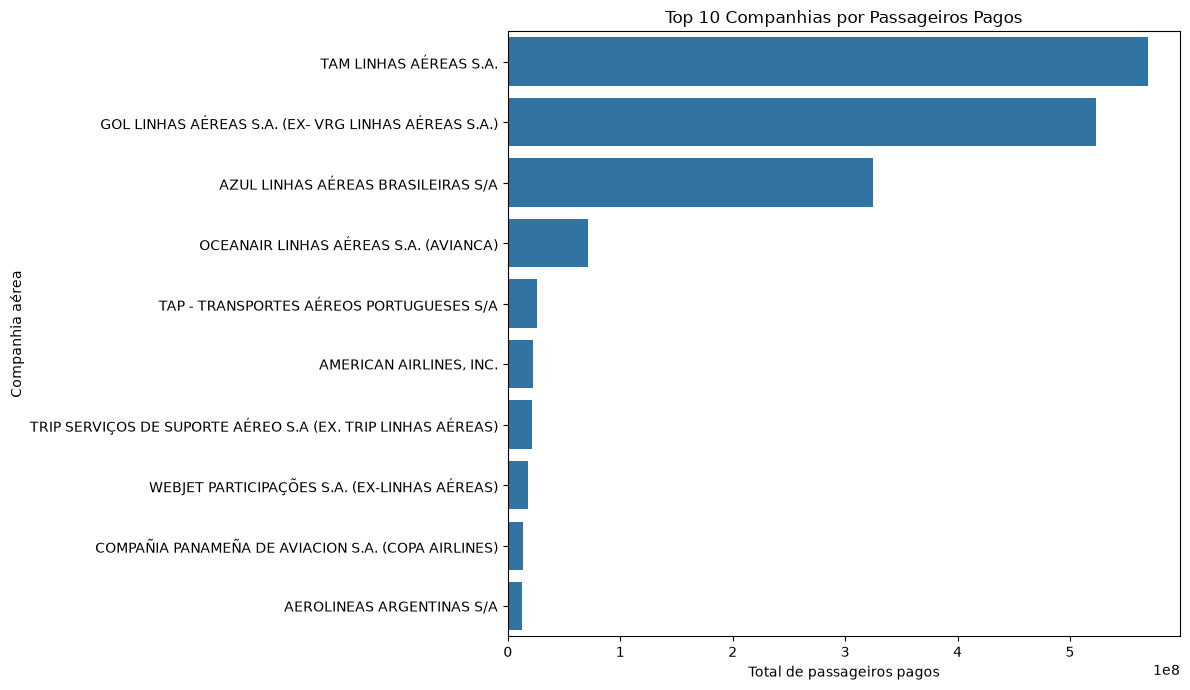

In [17]:
# 7. ANALISE 3 - COMPANHIAS COM MAIS PASSAGEIROS PAGOS
# ============================================================

print("\n" + "=" * 70)
print("ANALISE 3 - TOP 10 COMPANHIAS AEREAS")
print("=" * 70)

companhias = (
    dados.group_by("EMPRESA_NOME")
    .agg(
        pl.col("PASSAGEIROS_PAGOS")
        .sum()
        .alias("PASSAGEIROS_PAGOS")
    )
    .filter(pl.col("EMPRESA_NOME").is_not_null())
    .sort("PASSAGEIROS_PAGOS", descending=True)
    .head(10)
    .collect()
)

print(companhias)

df_companhias = companhias.to_pandas()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_companhias,
    x="PASSAGEIROS_PAGOS",
    y="EMPRESA_NOME"
)

plt.title("Top 10 Companhias por Passageiros Pagos")
plt.xlabel("Total de passageiros pagos")
plt.ylabel("Companhia aérea")
plt.tight_layout()
plt.show()

# ============================================================

## 16. Análise 4 — Rotas com mais registros
Identifica as dez rotas de origem e destino com mais registros.


ANALISE 4 - TOP 10 ROTAS AEREAS
shape: (10, 3)
┌───────────────────────────┬────────────────────────────┬─────────────────┐
│ AEROPORTO_DE_ORIGEM_SIGLA ┆ AEROPORTO_DE_DESTINO_SIGLA ┆ TOTAL_REGISTROS │
│ ---                       ┆ ---                        ┆ ---             │
│ str                       ┆ str                        ┆ u32             │
╞═══════════════════════════╪════════════════════════════╪═════════════════╡
│ SBGL                      ┆ SBGR                       ┆ 3038            │
│ SBGR                      ┆ SBGL                       ┆ 2645            │
│ KMIA                      ┆ SBKP                       ┆ 2315            │
│ SBGR                      ┆ SAEZ                       ┆ 2094            │
│ SBCT                      ┆ SBKP                       ┆ 2004            │
│ SBPA                      ┆ SBGR                       ┆ 1946            │
│ SAEZ                      ┆ SBGR                       ┆ 1936            │
│ SBBR                      

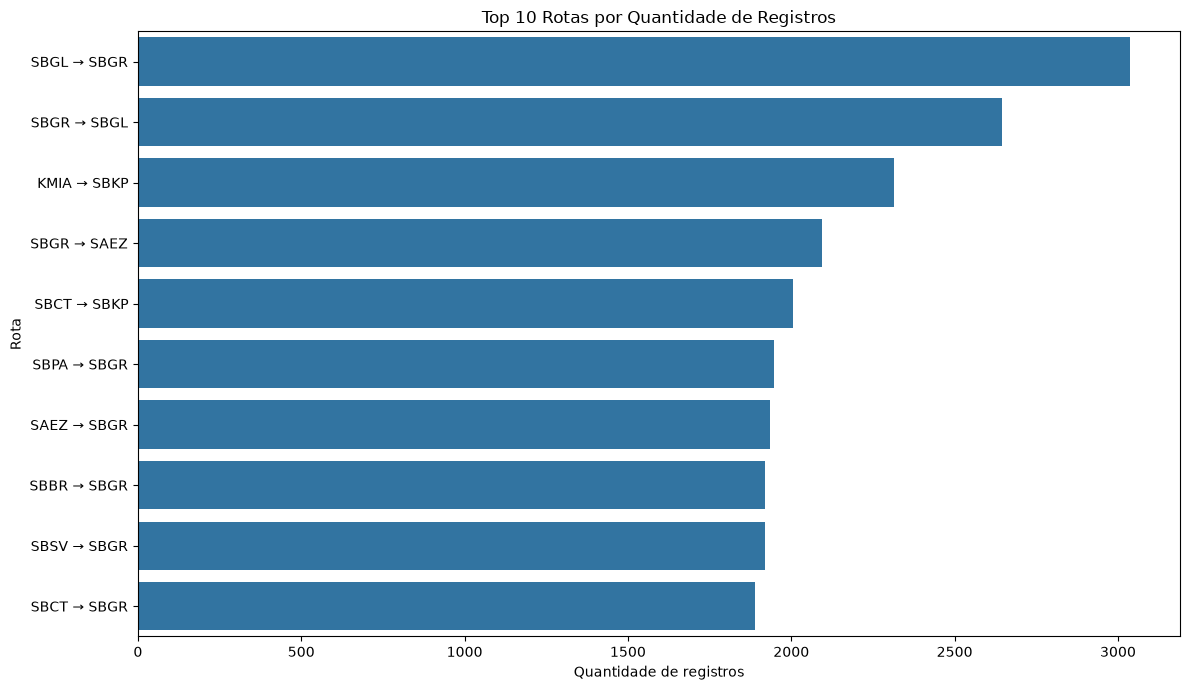

In [18]:
# 8. ANALISE 4 - ROTAS COM MAIS REGISTROS
# ============================================================

print("\n" + "=" * 70)
print("ANALISE 4 - TOP 10 ROTAS AEREAS")
print("=" * 70)

rotas = (
    dados.filter(
        pl.col("AEROPORTO_DE_ORIGEM_SIGLA").is_not_null()
        & pl.col("AEROPORTO_DE_DESTINO_SIGLA").is_not_null()
    )
    .group_by(
        [
            "AEROPORTO_DE_ORIGEM_SIGLA",
            "AEROPORTO_DE_DESTINO_SIGLA"
        ]
    )
    .agg(
        pl.len().alias("TOTAL_REGISTROS")
    )
    .sort("TOTAL_REGISTROS", descending=True)
    .head(10)
    .collect()
)

print(rotas)

df_rotas = rotas.to_pandas()

df_rotas["ROTA"] = (
    df_rotas["AEROPORTO_DE_ORIGEM_SIGLA"]
    + " → "
    + df_rotas["AEROPORTO_DE_DESTINO_SIGLA"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_rotas,
    x="TOTAL_REGISTROS",
    y="ROTA"
)

plt.title("Top 10 Rotas por Quantidade de Registros")
plt.xlabel("Quantidade de registros")
plt.ylabel("Rota")
plt.tight_layout()
plt.show()


# ============================================================

## 17. Análise 5 — Cobertura mensal por ano
Verifica quantos meses estão representados em cada ano.

In [19]:
# 9. ANALISE DA COBERTURA MENSAL POR ANO
# ============================================================

print("\n" + "=" * 70)
print("ANALISE 5 - COBERTURA MENSAL POR ANO")
print("=" * 70)

cobertura_mensal = (
    dados.group_by("ANO")
    .agg(
        pl.col("MES").n_unique().alias("MESES_REGISTRADOS"),
        pl.col("MES").min().alias("PRIMEIRO_MES"),
        pl.col("MES").max().alias("ULTIMO_MES"),
        pl.len().alias("TOTAL_REGISTROS")
    )
    .sort("ANO")
    .collect()
)

print(cobertura_mensal)

# ============================================================


ANALISE 5 - COBERTURA MENSAL POR ANO
shape: (19, 5)
┌──────┬───────────────────┬──────────────┬────────────┬─────────────────┐
│ ANO  ┆ MESES_REGISTRADOS ┆ PRIMEIRO_MES ┆ ULTIMO_MES ┆ TOTAL_REGISTROS │
│ ---  ┆ ---               ┆ ---          ┆ ---        ┆ ---             │
│ i64  ┆ u32               ┆ i64          ┆ i64        ┆ u32             │
╞══════╪═══════════════════╪══════════════╪════════════╪═════════════════╡
│ 2007 ┆ 12                ┆ 1            ┆ 12         ┆ 45856           │
│ 2008 ┆ 12                ┆ 1            ┆ 12         ┆ 38553           │
│ 2009 ┆ 12                ┆ 1            ┆ 12         ┆ 37983           │
│ 2010 ┆ 12                ┆ 1            ┆ 12         ┆ 44898           │
│ 2011 ┆ 12                ┆ 1            ┆ 12         ┆ 47638           │
│ …    ┆ …                 ┆ …            ┆ …          ┆ …               │
│ 2021 ┆ 12                ┆ 1            ┆ 12         ┆ 28660           │
│ 2022 ┆ 12                ┆ 1            ┆ 12 

## 18. Análise 6 — Carga transportada por ano
Compara a evolução anual de carga paga, carga gratuita e correio.


ANALISE 6 - CARGA TRANSPORTADA POR ANO
shape: (19, 4)
┌──────┬───────────────┬─────────────────┬────────────┐
│ ANO  ┆ CARGA_PAGA_KG ┆ CARGA_GRATIS_KG ┆ CORREIO_KG │
│ ---  ┆ ---           ┆ ---             ┆ ---        │
│ i64  ┆ i64           ┆ i64             ┆ i64        │
╞══════╪═══════════════╪═════════════════╪════════════╡
│ 2007 ┆ 922388457     ┆ 8404029         ┆ 85023889   │
│ 2008 ┆ 890690461     ┆ 9677920         ┆ 74698139   │
│ 2009 ┆ 750747337     ┆ 8539625         ┆ 79344381   │
│ 2010 ┆ 1029903883    ┆ 8866763         ┆ 105866952  │
│ 2011 ┆ 1136252714    ┆ 8131086         ┆ 124794247  │
│ …    ┆ …             ┆ …               ┆ …          │
│ 2021 ┆ 1291694195    ┆ 6893834         ┆ 74331428   │
│ 2022 ┆ 1352713426    ┆ 7332630         ┆ 74646868   │
│ 2023 ┆ 1307136494    ┆ 10041109        ┆ 76088134   │
│ 2024 ┆ 1437284147    ┆ 10340020        ┆ 76466059   │
│ 2025 ┆ 267887832     ┆ 3404438         ┆ 1161894    │
└──────┴───────────────┴─────────────────┴───────

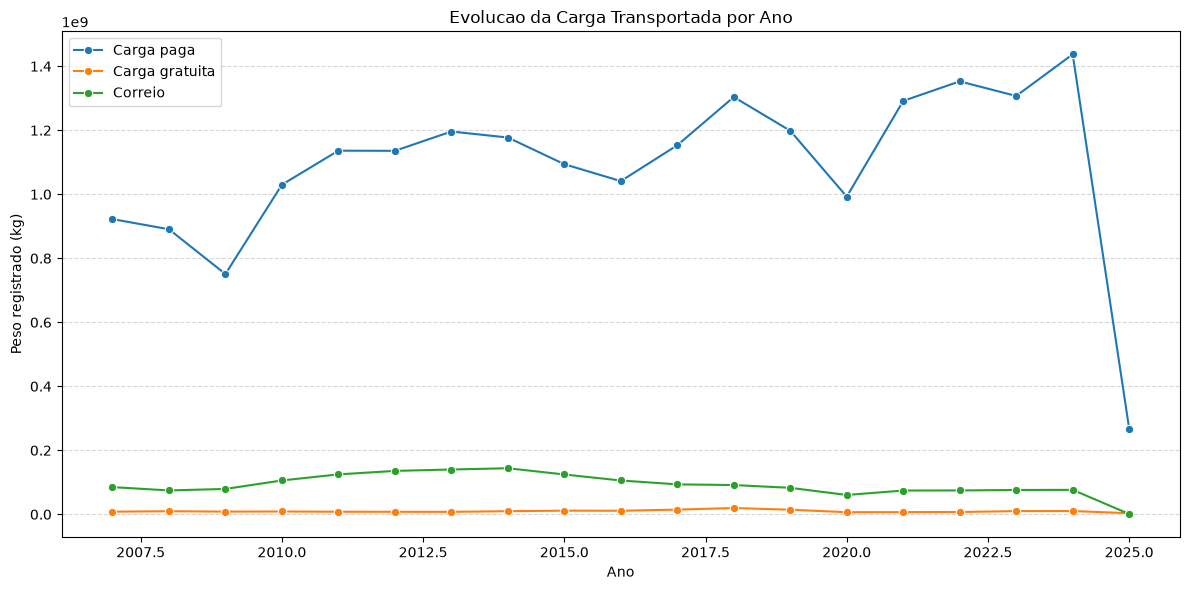


Analises iniciais concluidas!


In [20]:
# 10. ANALISE DE CARGA TRANSPORTADA POR ANO
# ============================================================

print("\n" + "=" * 70)
print("ANALISE 6 - CARGA TRANSPORTADA POR ANO")
print("=" * 70)

carga_ano = (
    dados.group_by("ANO")
    .agg(
        pl.col("CARGA_PAGA_KG").sum().alias("CARGA_PAGA_KG"),
        pl.col("CARGA_GRATIS_KG").sum().alias("CARGA_GRATIS_KG"),
        pl.col("CORREIO_KG").sum().alias("CORREIO_KG")
    )
    .sort("ANO")
    .collect()
)

print(carga_ano)

df_carga = carga_ano.to_pandas()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_carga,
    x="ANO",
    y="CARGA_PAGA_KG",
    marker="o",
    label="Carga paga"
)

sns.lineplot(
    data=df_carga,
    x="ANO",
    y="CARGA_GRATIS_KG",
    marker="o",
    label="Carga gratuita"
)

sns.lineplot(
    data=df_carga,
    x="ANO",
    y="CORREIO_KG",
    marker="o",
    label="Correio"
)

plt.title("Evolucao da Carga Transportada por Ano")
plt.xlabel("Ano")
plt.ylabel("Peso registrado (kg)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


print("\nAnalises iniciais concluidas!")